<a href="https://colab.research.google.com/github/Renatomsa19/InteligenciaArtifical_LinguagensFormais_Automatos/blob/main/Sistema_Especialista/SISTEMAESPECIALISTA_ES_N1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Aprendizado de Máquina – Introdução
## Sistema especialista com aprendizado supervisionado

**Renato Miranda de Souza Araujo Alves** – RGM: 38989611

Inteligência Artificial e LFA | Sistemas Especialistas

Execute este notebook no Google Colab ou no Jupyter, de cima para baixo. No Colab: Arquivo > Fazer upload de notebook > selecione este arquivo.

**Objetivo:** treinar um classificador e usar sua previsão como fato em um sistema especialista que recomenda quantos litros abastecer antes de uma viagem.

**Leitura:** [Guia IBM](https://www.ibm.com/br-pt/think/machine-learning) e [aprendizado supervisionado](https://www.ibm.com/br-pt/think/topics/supervised-learning).

**Responda:** o que é aprendizado de máquina? O que são atributos e rótulos? Como classificação difere de regressão? Por que separar treino e teste?

Os dados abaixo são fictícios, muito pequenos e deliberadamente simples. Este exemplo não substitui o cálculo real de consumo de um veículo.

### O problema escolhido
Saber quanto abastecer antes de uma viagem. Abastecer pouco pode deixar o motorista sem combustível no caminho; abastecer sem precisar faz perder tempo e dinheiro.

| Elemento | Definição |
|---|---|
| **Entradas (atributos)** | `distancia_km` e `consumo_km_l` |
| **Rótulo** | `gasto` (`alto` ou `baixo`) |
| **Outros fatos (informados pelo usuário)** | capacidade do tanque e litros que já estão no tanque |
| **Saída** | quantos litros abastecer, a regra aplicada e a explicação |

## Respostas – Estudo inicial

**1. O que é aprendizado de máquina?**  
É uma área da Inteligência Artificial em que o computador aprende padrões a partir de dados, em vez de seguir apenas regras programadas à mão. Depois de aprender, ele usa esses padrões para fazer previsões sobre casos novos. Neste projeto, o modelo aprende com exemplos de viagens a prever se o gasto de gasolina será alto ou baixo.

**2. O que caracteriza o aprendizado supervisionado?**  
O modelo é treinado com exemplos que já têm a resposta correta (dados rotulados). Ele compara suas previsões com essas respostas e se ajusta até errar o mínimo possível. Aqui, cada viagem do dataset já vem marcada como gasto alto ou baixo.

**3. O que são atributos e rótulos?**  
**Atributos** são as entradas, ou seja, as características de cada exemplo que o modelo usa para decidir. Neste projeto: `distancia_km` e `consumo_km_l`.  
**Rótulo** é a resposta conhecida que o modelo deve aprender a prever. Neste projeto: `gasto` (alto ou baixo).

**4. Como classificação difere de regressão?**  
A **classificação** prevê uma **categoria** (ex.: gasto alto ou baixo, spam ou não spam).  
A **regressão** prevê um **valor numérico contínuo** (ex.: quantos litros a viagem vai gastar, preço de uma casa).  
Este projeto usa classificação.

**5. Por que separar treino e teste?**  
Para avaliar o modelo com exemplos que ele **não viu** durante o treinamento. Se testássemos com os mesmos dados do treino, o modelo poderia apenas "decorar" as respostas, e a acurácia pareceria melhor do que realmente é. Aqui, 12 viagens foram usadas para treinar e 4 para testar.

## 1. Preparar o ambiente

No Colab, as bibliotecas geralmente já estão disponíveis. Se o próximo bloco apresentar `ModuleNotFoundError`, execute em uma nova célula: `%pip install pandas scikit-learn matplotlib` e tente novamente.

In [1]:
# Importação das bibliotecas
import math
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
print("Bibliotecas carregadas.")

Bibliotecas carregadas.


## 2. Dataset rotulado
Cada linha é uma viagem. As entradas são a distância da viagem (km) e o consumo do carro (km por litro). O rótulo `gasto` é a resposta conhecida: `baixo` ou `alto`.

**Sobre o dataset**
- Tamanho: 16 viagens (8 de cada classe)
- Origem: dados simulados (fictícios), criados para esta atividade
- Critério de rotulagem: `alto` quando a viagem gasta mais de 10 litros (distância ÷ consumo > 10); `baixo` nos demais casos
- Em um projeto real, os rótulos viriam de viagens de verdade, com o consumo medido no abastecimento

In [2]:
# Dataset fictício: 16 viagens (8 com gasto baixo, 8 com gasto alto)
dados = pd.DataFrame({
    "distancia_km": [30, 50, 60, 80, 100, 40, 90, 70,
                     200, 250, 180, 300, 220, 160, 280, 150],
    "consumo_km_l": [10, 8, 12, 10, 14, 9, 12, 15,
                     10, 12, 8, 14, 9, 10, 15, 8],
    "gasto": ["baixo"] * 8 + ["alto"] * 8
})
print(dados.to_string(index=False))
print("\nQuantidade por classe:")
print(dados["gasto"].value_counts())

 distancia_km  consumo_km_l gasto
           30            10 baixo
           50             8 baixo
           60            12 baixo
           80            10 baixo
          100            14 baixo
           40             9 baixo
           90            12 baixo
           70            15 baixo
          200            10  alto
          250            12  alto
          180             8  alto
          300            14  alto
          220             9  alto
          160            10  alto
          280            15  alto
          150             8  alto

Quantidade por classe:
gasto
baixo    8
alto     8
Name: count, dtype: int64


## 3. Separar treinamento e teste

`X` contém atributos e `y` contém o rótulo. Reservamos 25% dos exemplos para teste: são 12 exemplos de treino e 4 de teste. `stratify` preserva a proporção das classes; `random_state` torna a divisão reproduzível. O rótulo nunca entra em `X`.

In [3]:
# Separação de atributos (X) e rótulo (y), e divisão treino/teste
X = dados[["distancia_km", "consumo_km_l"]]
y = dados["gasto"]
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Treino:", len(X_treino), "| Teste:", len(X_teste))

Treino: 12 | Teste: 4


## 4. Treinar e avaliar

`fit` aprende padrões somente no treino; `predict` gera previsões. Acurácia é a fração de acertos no teste. Na matriz, linhas são classes reais e colunas são previstas. Não ajuste o modelo repetidamente para acertar este mesmo teste: use validação separada se fizer ajustes.

Acurácia no teste: 100.0%
       baixo  alto
baixo      2     0
alto       0     2


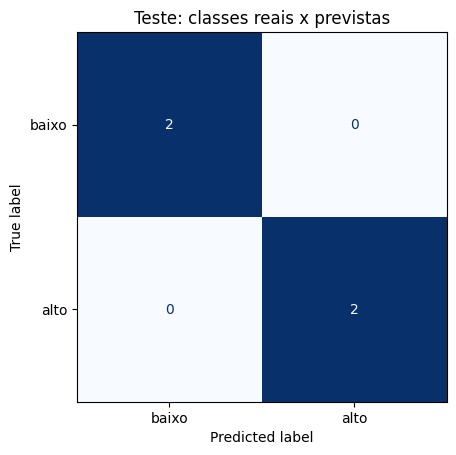

Condições aprendidas:
|--- distancia_km <= 125.00
|   |--- class: baixo
|--- distancia_km >  125.00
|   |--- class: alto



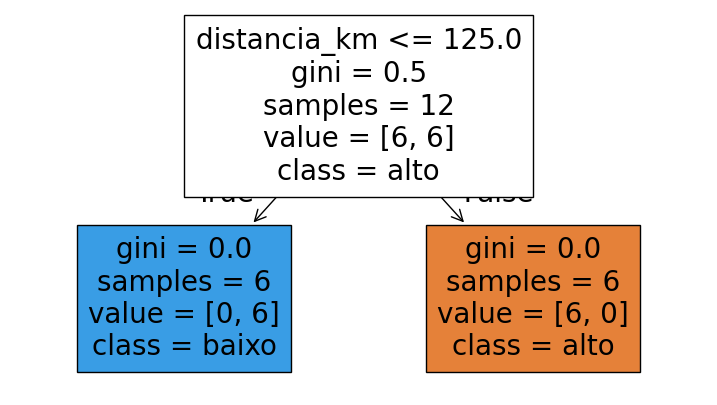

In [4]:
# Treinamento da árvore de decisão
modelo = DecisionTreeClassifier(max_depth=2, random_state=42)
modelo.fit(X_treino, y_treino)
previsoes = modelo.predict(X_teste)
print(f"Acurácia no teste: {accuracy_score(y_teste, previsoes):.1%}")

# Matriz de confusão
classes = ["baixo", "alto"]
matriz = confusion_matrix(y_teste, previsoes, labels=classes)
print(pd.DataFrame(matriz, index=classes, columns=classes))
ConfusionMatrixDisplay(matriz, display_labels=classes).plot(
    cmap="Blues", colorbar=False
)
plt.title("Teste: classes reais x previstas")
plt.show()

# Condições aprendidas pela árvore
print("Condições aprendidas:")
print(export_text(modelo, feature_names=list(X.columns)))
plt.figure(figsize=(9, 5))
plot_tree(modelo, feature_names=list(X.columns),
          class_names=list(modelo.classes_), filled=True)
plt.show()

### Entendendo os Termos da Árvore de Decisão

Cada nó (caixa) na visualização da árvore contém três métricas:

**Gini:** mede a mistura dos dados no nó. Varia de 0.0 (todos da mesma classe) a 0.5 (metade de cada classe).

**Samples:** número de viagens do treino que chegaram ao nó. A raiz começa com 12 amostras; após a divisão `distancia_km <= 125.0`, cada lado fica com 6.

**Value:** quantidade de exemplos por classe, na ordem `[alto, baixo]`. Na raiz, `value = [6, 6]`.

**Interpretação:** como as classes foram construídas com separação simples e existem apenas quatro casos de teste, mesmo 100% de acurácia não demonstra eficácia em situações reais. A árvore mostra condições aprendidas; as regras de recomendação abaixo foram escritas por pessoas.

## 5. Base de conhecimento e motor de inferência

A previsão do modelo vira um fato: o **gasto** (alto ou baixo). Com ele, o sistema define a margem de segurança (10% para gasto baixo, 20% para gasto alto) e calcula quantos litros são necessários. Comparando com os litros que já estão no tanque e com a capacidade do tanque, surge o segundo fato: a **situação do tanque**.

- **suficiente:** os litros no tanque já cobrem a viagem com margem;
- **falta_cabe:** falta combustível, mas o que falta cabe no tanque;
- **nao_cabe:** a viagem precisa de mais combustível do que o tanque comporta.

O motor procura a regra compatível e apresenta recomendação e justificativa.

- **R1:** SE situação = suficiente, ENTÃO não precisa abastecer.
- **R2:** SE gasto = baixo E situação = falta_cabe, ENTÃO abastecer os litros que faltam.
- **R3:** SE gasto = alto E situação = falta_cabe, ENTÃO abastecer os litros que faltam e, se possível, completar o tanque.
- **R4:** SE situação = nao_cabe, ENTÃO encher o tanque e planejar uma parada no caminho.

**Origem das regras:** escrevi as regras a partir do que um motorista faz antes de viajar: conferir se o combustível dá para o trajeto e deixar uma sobra para imprevistos. Em viagens longas a sobra é maior (20%), porque o erro do consumo médio se acumula com a distância. As margens foram escolhidas por mim, e as regras não foram geradas pelo modelo.

In [5]:
# Base de conhecimento ("qualquer" = a regra vale para os dois valores)
regras = [
    {"id": "R1", "gasto": "qualquer", "situacao": "suficiente",
     "acao": "Não precisa abastecer."},
    {"id": "R2", "gasto": "baixo", "situacao": "falta_cabe",
     "acao": "Abastecer pelo menos {abastecer} litros."},
    {"id": "R3", "gasto": "alto", "situacao": "falta_cabe",
     "acao": "Abastecer pelo menos {abastecer} litros; como a viagem é longa, se possível complete o tanque ({completar} litros)."},
    {"id": "R4", "gasto": "qualquer", "situacao": "nao_cabe",
     "acao": "Encher o tanque ({completar} litros) e planejar uma parada para abastecer antes de {km_parada} km."}
]

# Motor de inferência
def aplicar_regras(gasto, situacao):
    for regra in regras:
        if (regra["gasto"] in (gasto, "qualquer") and
                regra["situacao"] == situacao):
            return regra
    raise ValueError("Nenhuma regra compatível com os fatos.")

## 6. Integrar o modelo ao sistema especialista

A função valida os valores, usa o modelo para prever o gasto, calcula os litros necessários com a margem de segurança, define a situação do tanque e aplica as regras. Valores fora dos intervalos observados no treino recebem um aviso, pois a previsão pode ser menos confiável.

In [6]:
# Integração: previsão do modelo + regras do sistema especialista
def orientar_viagem(distancia, consumo, capacidade_tanque, litros_no_tanque):
    if distancia <= 0 or consumo <= 0 or capacidade_tanque <= 0:
        raise ValueError("Distância, consumo e capacidade devem ser maiores que zero.")
    if not 0 <= litros_no_tanque <= capacidade_tanque:
        raise ValueError("Litros no tanque devem estar entre 0 e a capacidade do tanque.")

    # 1. O modelo prevê o gasto (fato 1)
    novo_caso = pd.DataFrame([{"distancia_km": distancia, "consumo_km_l": consumo}])
    gasto = modelo.predict(novo_caso)[0]

    # 2. Cálculo dos litros necessários com margem de segurança
    margem = 0.20 if gasto == "alto" else 0.10
    litros_viagem = distancia / consumo
    litros_necessarios = litros_viagem * (1 + margem)

    # 3. Situação do tanque (fato 2)
    if litros_no_tanque >= litros_necessarios:
        situacao = "suficiente"
    elif litros_necessarios <= capacidade_tanque:
        situacao = "falta_cabe"
    else:
        situacao = "nao_cabe"

    # 4. Inferência
    regra = aplicar_regras(gasto, situacao)
    recomendacao = regra["acao"].format(
        abastecer=math.ceil((litros_necessarios - litros_no_tanque) * 10) / 10,
        completar=round(capacidade_tanque - litros_no_tanque, 1),
        km_parada=int(capacidade_tanque * consumo / (1 + margem))
    )
    fora = any(
        not X_treino[c].min() <= novo_caso[c].iloc[0] <= X_treino[c].max()
        for c in X.columns
    )
    return {
        "gasto_previsto": gasto,
        "litros_da_viagem": round(litros_viagem, 1),
        "litros_necessarios_com_margem": round(litros_necessarios, 1),
        "situacao_do_tanque": situacao,
        "regra": regra["id"],
        "recomendacao": recomendacao,
        "explicacao": (f"Gasto previsto: {gasto} (margem de {margem:.0%}); "
                       f"tem {litros_no_tanque} L de {capacidade_tanque} L; "
                       f"precisa de {litros_necessarios:.1f} L."),
        "aviso": ("Entrada fora dos intervalos observados no treino."
                  if fora else "Exemplo didático; orientação sujeita a revisão humana.")
    }

# Casos novos, que não são utilizados no treinamento
# (distância km, consumo km/l, capacidade do tanque L, litros no tanque)
casos = [(40, 10, 50, 12), (60, 12, 16, 2), (200, 12, 50, 5), (250, 10, 16, 2)]
for i, (distancia, consumo, capacidade, litros) in enumerate(casos, 1):
    print(f"\nCASO {i}: {distancia} km; {consumo} km/l; tanque de {capacidade} L com {litros} L")
    for campo, valor in orientar_viagem(distancia, consumo, capacidade, litros).items():
        print(f"{campo}: {valor}")


CASO 1: 40 km; 10 km/l; tanque de 50 L com 12 L
gasto_previsto: baixo
litros_da_viagem: 4.0
litros_necessarios_com_margem: 4.4
situacao_do_tanque: suficiente
regra: R1
recomendacao: Não precisa abastecer.
explicacao: Gasto previsto: baixo (margem de 10%); tem 12 L de 50 L; precisa de 4.4 L.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 2: 60 km; 12 km/l; tanque de 16 L com 2 L
gasto_previsto: baixo
litros_da_viagem: 5.0
litros_necessarios_com_margem: 5.5
situacao_do_tanque: falta_cabe
regra: R2
recomendacao: Abastecer pelo menos 3.5 litros.
explicacao: Gasto previsto: baixo (margem de 10%); tem 2 L de 16 L; precisa de 5.5 L.
aviso: Exemplo didático; orientação sujeita a revisão humana.

CASO 3: 200 km; 12 km/l; tanque de 50 L com 5 L
gasto_previsto: alto
litros_da_viagem: 16.7
litros_necessarios_com_margem: 20.0
situacao_do_tanque: falta_cabe
regra: R3
recomendacao: Abastecer pelo menos 15.0 litros; como a viagem é longa, se possível complete o tanque (45 litros)

## 7. Experimente uma consulta

Altere os quatro valores abaixo e execute novamente. Compare casos com a mesma distância e diferentes quantidades de combustível no tanque. Qual componente modifica a recomendação?

In [7]:
# Variáveis de entrada para uma consulta
distancia = 60
consumo = 12
capacidade_tanque = 16
litros_no_tanque = 10

resultado = orientar_viagem(distancia, consumo, capacidade_tanque, litros_no_tanque)
for campo, valor in resultado.items():
    print(f"{campo}: {valor}")

gasto_previsto: baixo
litros_da_viagem: 5.0
litros_necessarios_com_margem: 5.5
situacao_do_tanque: suficiente
regra: R1
recomendacao: Não precisa abastecer.
explicacao: Gasto previsto: baixo (margem de 10%); tem 10 L de 16 L; precisa de 5.5 L.
aviso: Exemplo didático; orientação sujeita a revisão humana.


## 8. Análise dos resultados

**Casos**
- **Caso 1** (40 km, 10 km/l, tanque de 50 L com 12 L): a viagem gasta 4 L; gasto **baixo**, margem de 10% → precisa de 4,4 L. Já tem 12 L → **R1**, não precisa abastecer.
- **Caso 2** (60 km, 12 km/l, tanque de 16 L com 2 L): a viagem gasta 5 L; gasto **baixo** → precisa de 5,5 L. Faltam 3,5 L, que cabem no tanque → **R2**, abastecer pelo menos 3,5 L.
- **Caso 3** (200 km, 12 km/l, tanque de 50 L com 5 L): a viagem gasta 16,7 L; gasto **alto**, margem de 20% → precisa de 20 L. Faltam 15 L → **R3**, abastecer pelo menos 15 L e, se possível, completar o tanque.
- **Caso 4** (250 km, 10 km/l, tanque de 16 L com 2 L): a viagem gasta 25 L; gasto **alto** → precisa de 30 L, mais do que o tanque comporta → **R4**, encher o tanque e parar para abastecer antes de 133 km.

**Perguntas para analisar o resultado**

**Qual parte do programa aprende com os dados?**  
A árvore de decisão (`modelo.fit`). Ela descobriu sozinha que viagens acima de 125 km têm gasto alto.

**Qual parte aplica regras humanas?**  
A base de conhecimento (`regras`) e o motor de inferência (`aplicar_regras`). As regras R1 a R4 e as margens de segurança (10% e 20%) foram definidas por pessoas.

**Por que a capacidade do tanque e os litros abastecidos não aparecem entre os atributos do modelo?**  
Porque eles não mudam quanto a viagem gasta; só mudam a decisão de abastecer. Por isso são fatos usados apenas pelas regras.

**O que acontece ao mudar apenas esses fatos?**  
A previsão do modelo continua a mesma; só mudam a situação do tanque, a regra aplicada e a recomendação. Exemplo: 60 km a 12 km/l com 2 L no tanque → R2; com 10 L no tanque → R1.

**Um resultado de 100% em quatro casos de teste é suficiente para uso real?**  
Não. São poucos casos, os dados são fictícios e as classes foram construídas para serem fáceis de separar.

**Limitações:** a árvore aprendeu a separar só pela distância; um carro que gasta muito em uma viagem média recebe a margem menor (10%). O consumo informado pelo usuário é uma média e muda com trânsito, ar-condicionado, estrada ou cidade. As margens de segurança foram escolhidas pela equipe, não validadas com dados reais.

**Exemplos pouco representados**
- Não há viagens entre 100 km e 150 km no dataset, justamente onde a árvore faz o corte (125 km). Casos nessa faixa são os mais incertos.
- Carros que fazem menos de 8 km/l ou mais de 15 km/l não aparecem no treino; o sistema mostra um aviso quando isso acontece.
- Viagens muito curtas ou muito longas também ficam fora do intervalo visto no treino.

**Dados pessoais**
O sistema não pede nome, placa nem localização, só números da viagem e do carro. Se fosse usado de verdade com o histórico de viagens de uma pessoa, esses dados mostrariam por onde ela anda. Nesse caso seria preciso pedir consentimento, guardar só o necessário e seguir a LGPD.

## Referências
- IBM. Guia de Aprendizado de Máquina: https://www.ibm.com/br-pt/think/machine-learning
- IBM. Aprendizado supervisionado: https://www.ibm.com/br-pt/think/topics/supervised-learning
- scikit-learn. DecisionTreeClassifier: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn. train_test_split: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html